## Análisis de modelos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)
from xgboost import XGBClassifier  
from sklearn.metrics import f1_score
from itertools import product
import joblib


In [2]:
df = pd.read_csv("../data/raw/billboard_processed.csv")

df.head()

,performer,spotify_genre,spotify_track_duration_ms,spotify_track_explicit,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature,acoustic_mood_cluster,top30
0,The Weeknd,"['canadian contemporary r&b', 'canadian pop', ...",201573.0,False,0.513,1.0,-4.075,1.0,0.0629,0.000209,171.017,4.0,intense_aggressive_drive,1
1,LMFAO Featuring Lauren Bennett & GoonRock,"['dance pop', 'pop', 'pop rap']",262173.0,False,0.750,5.0,-4.210,0.0,0.1420,0.000000,129.993,4.0,intense_aggressive_drive,1
2,Adele,"['british soul', 'pop', 'uk pop']",228293.0,False,0.729,8.0,-5.119,1.0,0.0294,0.000000,104.945,4.0,balanced_acoustic_pop,1
3,Post Malone,"['dfw rap', 'melodic rap', 'rap']",215280.0,False,0.695,0.0,-3.497,1.0,0.0395,0.002440,120.042,4.0,balanced_acoustic_pop,1
4,Los Del Rio,"['deep norteno', 'duranguense', 'norteno', 'no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop,1


## Analizar variable "top30":

top30
0    18112
1    12659
Name: count, dtype: int64

Porcentajes:
top30
0    58.860616
1    41.139384
Name: proportion, dtype: float64


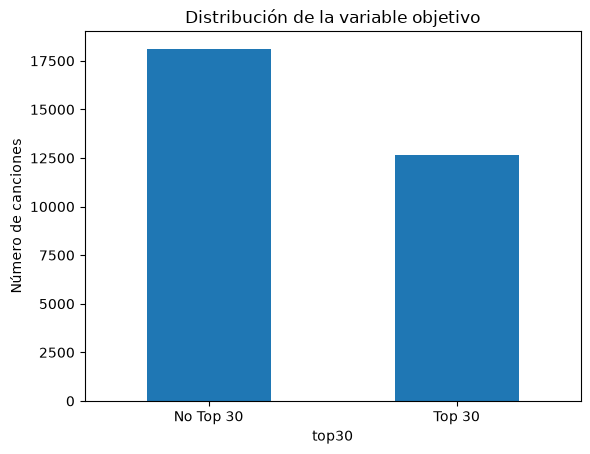

In [3]:
print(df["top30"].value_counts())
print("\nPorcentajes:")
print(df["top30"].value_counts(normalize=True) * 100)

df["top30"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.xticks([0, 1], ["No Top 30", "Top 30"])
plt.ylabel("Número de canciones")
plt.title("Distribución de la variable objetivo")
plt.show()

## Separamos train y test:

In [4]:
X = df.drop(columns=["top30"])
y = df["top30"]

X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.10, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.10, random_state=42, stratify=y_resto)


print(X_train.shape,X_val.shape, X_test.shape)
print('En train:', round(y_train.mean() * 100, 2), "%", 'En validación: ',round(y_val.mean()*100,2),"%" , '  en test:', round(y_test.mean() * 100, 2), "%")

(24923, 13) (2770, 13) (3078, 13)
En train: 41.14 % En validación:  41.16 %   en test: 41.13 %


In [5]:
print("Columnas de X:")
print(X_train.columns.tolist())

print("\nDimensiones:")
print(X_train.shape)

print("\nColumnas con nulos:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Columnas de X:
['performer', 'spotify_genre', 'spotify_track_duration_ms', 'spotify_track_explicit', 'danceability', 'key', 'loudness', 'mode', 'speechiness', 'instrumentalness', 'tempo', 'time_signature', 'acoustic_mood_cluster']

Dimensiones:
(24923, 13)

Columnas con nulos:
spotify_track_duration_ms    2976
spotify_track_explicit       2976
danceability                 3025
key                          3025
loudness                     3025
mode                         3025
speechiness                  3025
instrumentalness             3025
tempo                        3025
time_signature               3025
dtype: int64


## Aplicamos el análisis en X_train

In [6]:
variables_media = ["danceability", "speechiness", "instrumentalness", "tempo"]
variables_mediana = ["loudness"]
variables_moda = ["key", "mode", "time_signature"]

globales_mediana = ["spotify_track_duration_ms"]
globales_moda = ["spotify_track_explicit"]

cluster_col = "acoustic_mood_cluster"
columnas_cluster = variables_media + variables_mediana + variables_moda
columnas_globales = globales_mediana + globales_moda
columnas = columnas_cluster + columnas_globales

print("Nulos TRAIN antes:")
print(X_train[columnas].isna().sum())

stats_cluster = {}   # {columna: Serie indexada por cluster}
stats_global = {}    # {columna: valor global}

for col in variables_media:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].mean()
    stats_global[col] = X_train[col].mean()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_mediana:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].median()
    stats_global[col] = X_train[col].median()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_moda:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].agg(
        lambda x: x.mode().iloc[0] if not x.mode().empty else float("nan")
    )
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_mediana:
    stats_global[col] = X_train[col].median()
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_moda:
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")
    X_train[col] = X_train[col].fillna(stats_global[col])

print("\nNulos TRAIN después:")
print(X_train[columnas].isna().sum())

print("\nEstadísticas globales guardadas (train):")
print(stats_global)

Nulos TRAIN antes:
danceability                 3025
speechiness                  3025
instrumentalness             3025
tempo                        3025
loudness                     3025
key                          3025
mode                         3025
time_signature               3025
spotify_track_duration_ms    2976
spotify_track_explicit       2976
dtype: int64

Nulos TRAIN después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64

Estadísticas globales guardadas (train):
{'danceability': np.float64(0.6020063932779248), 'speechiness': np.float64(0.08950473102566445), 'instrumentalness': np.float64(0.032657926696501964), 'tempo': np.float64(121.06935149328706), 'loudness': -8.13, 'key': np.float64(0.0), 'mode'

C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_11548\3074567703.py:53: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train[col] = X_train[col].fillna(stats_global[col])


## Rellenamos nulos en X_val 

In [7]:
print("Nulos VAL antes:")
print(X_val[columnas].isna().sum())

# Con cluster
for col in columnas_cluster:
    valor_cluster = X_val[cluster_col].map(stats_cluster[col])
    X_val[col] = X_val[col].fillna(valor_cluster)
    X_val[col] = X_val[col].fillna(stats_global[col])

# Solo global
for col in columnas_globales:
    X_val[col] = X_val[col].fillna(stats_global[col])

print("\nNulos VAL después:")
print(X_val[columnas].isna().sum())

Nulos VAL antes:
danceability                 319
speechiness                  319
instrumentalness             319
tempo                        319
loudness                     319
key                          319
mode                         319
time_signature               319
spotify_track_duration_ms    315
spotify_track_explicit       315
dtype: int64

Nulos VAL después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_11548\3902017654.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_val[col] = X_val[col].fillna(stats_global[col])


## Rellenamos nulos en X_test

In [8]:
print("Nulos TEST antes:")
print(X_test[columnas].isna().sum())

# Con cluster
for col in columnas_cluster:
    valor_cluster = X_test[cluster_col].map(stats_cluster[col])
    X_test[col] = X_test[col].fillna(valor_cluster)
    X_test[col] = X_test[col].fillna(stats_global[col])

# Solo global
for col in columnas_globales:
    X_test[col] = X_test[col].fillna(stats_global[col])

print("\nNulos TEST después:")
print(X_test[columnas].isna().sum())

Nulos TEST antes:
danceability                 365
speechiness                  365
instrumentalness             365
tempo                        365
loudness                     365
key                          365
mode                         365
time_signature               365
spotify_track_duration_ms    359
spotify_track_explicit       359
dtype: int64

Nulos TEST después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_11548\387698589.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test[col] = X_test[col].fillna(stats_global[col])


In [9]:

print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())

Train: 0
Validation: 0


## Realizamos OneHotEncoder
- A las variables de tipo texto las convertimos en números ya que la regresión logística se hace con números.
- Tras realizar la ejeccución nos dimos cuenta que siguiendo este hilo daba sobreajuste.

In [10]:
texto = ["performer", "spotify_genre", "acoustic_mood_cluster", "spotify_track_explicit"]
encoder = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)
encoder.fit(X_train[texto])  
nombres = encoder.get_feature_names_out(texto)
print(nombres)

cat_train = pd.DataFrame(encoder.transform(X_train[texto]), columns=nombres, index=X_train.index)
cat_val = pd.DataFrame(encoder.transform(X_val[texto]), columns=nombres, index=X_val.index)
cat_test = pd.DataFrame(encoder.transform(X_test[texto]), columns=nombres, index=X_test.index)

X_train = pd.concat([X_train.drop(columns=texto), cat_train], axis=1)
X_val =  pd.concat([X_val.drop(columns=texto), cat_val], axis=1)
X_test = pd.concat([X_test.drop(columns=texto), cat_test], axis=1)
print('Columnas del modelo:', X_train.shape[1])
X_train.head()

print("Nulos después del OneHotEncoder:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())


['performer_"Little" Jimmy Dickens' 'performer_"Pookie" Hudson'
 'performer_"Weird Al" Yankovic' ...
 'acoustic_mood_cluster_intense_aggressive_drive'
 'acoustic_mood_cluster_moody_melancholic' 'spotify_track_explicit_True']


c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Columnas del modelo: 11001
Nulos después del OneHotEncoder:
Train: 0
Validation: 0
Test: 0


## Adaptamos los datos a XGBoost
- XGBoost no permite ciertos caracteres como [] o <>, quitamos esos caracteres.

In [11]:
X_train.columns = X_train.columns.str.replace(r'[\[\]<>]', '', regex=True)
X_val.columns = X_val.columns.str.replace(r'[\[\]<>]', '', regex=True)

## Definimos la función evaluar

In [12]:
def evaluar(nombre, modelo, X, y):

    y_pred = modelo.predict(X)
    y_prob = modelo.predict_proba(X)[:, 1]

    print("Modelo",nombre)
    print("F1:", round(f1_score(y, y_pred), 3))
    print("Recall:", round(recall_score(y, y_pred), 3))
    print("Precisión:", round(precision_score(y, y_pred), 3))
    print("AUC:", round(roc_auc_score(y, y_prob), 3))

## XGBoost por defecto 

In [13]:
xgboost_defecto = XGBClassifier(random_state=42)
xgboost_defecto.fit(X_train, y_train)
evaluar("XGBoost por defecto", xgboost_defecto, X_val, y_val)

Modelo XGBoost por defecto
F1: 0.443
Recall: 0.318
Precisión: 0.73
AUC: 0.693


## Realizamos matriz de confusión

In [14]:
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_val_esc = scaler.transform(X_val)

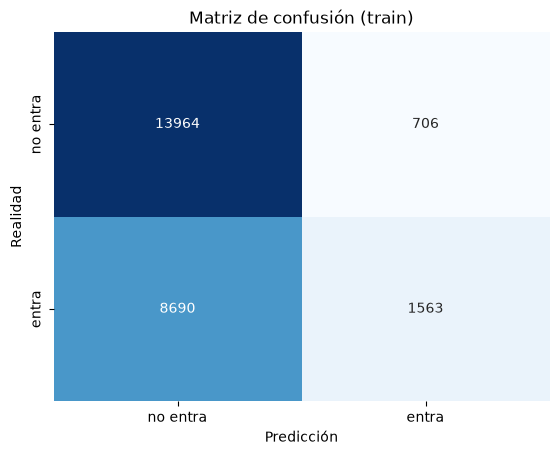

scikit-learn -> accuracy 0.623   precision 0.689   recall 0.152   F1 0.250
AUC: 0.651


In [15]:
pred_train = xgboost_defecto.predict(X_train_esc)     
prob_train = xgboost_defecto.predict_proba(X_train_esc)[:, 1]  

cm = confusion_matrix(y_train, pred_train)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (train)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_train, pred_train):.3f}   '
      f'precision {precision_score(y_train, pred_train):.3f}   '
      f'recall {recall_score(y_train, pred_train):.3f}   F1 {f1_score(y_train, pred_train):.3f}')

print('AUC:', round(roc_auc_score(y_train, prob_train), 3))

## Definiendo hiperparametros 

In [16]:
n_estimators = [100, 300, 500]
learning_rate = [0.03, 0.05, 0.1]
max_depth = [3, 5, 7]

## XGBoost ajustado

In [17]:
mejor_f1 = 0
mejor_modelo = None
mejores_parametros = None
for n, lr, profundidad in product(n_estimators, learning_rate, max_depth):

    modelo = XGBClassifier(
        random_state=42,
        n_estimators=n,
        learning_rate=lr,
        max_depth=profundidad
    )

    modelo.fit(X_train, y_train)

    y_pred = modelo.predict(X_val)

    f1 = f1_score(y_val, y_pred)

    if f1 > mejor_f1:
        mejor_f1 = f1
        mejor_modelo = modelo
        mejores_parametros = modelo.get_params()

print("Mejor F1:", mejor_f1)
print("Mejor modelo:", mejores_parametros)

Mejor F1: 0.471563981042654
Mejor modelo: {'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 7, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 500, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}


## Realizamos matriz de confusión

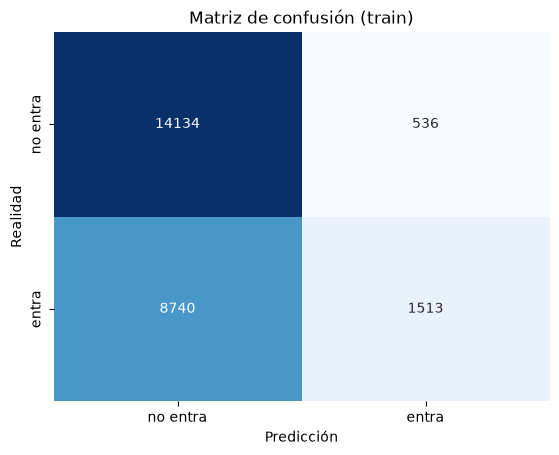

scikit-learn -> accuracy 0.628   precision 0.738   recall 0.148   F1 0.246
AUC: 0.659


In [18]:
pred_train = mejor_modelo.predict(X_train_esc)     
prob_train = mejor_modelo.predict_proba(X_train_esc)[:, 1]  

cm = confusion_matrix(y_train, pred_train)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (train)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_train, pred_train):.3f}   '
      f'precision {precision_score(y_train, pred_train):.3f}   '
      f'recall {recall_score(y_train, pred_train):.3f}   F1 {f1_score(y_train, pred_train):.3f}')

print('AUC:', round(roc_auc_score(y_train, prob_train), 3))

## Probamos el modelo con test

In [20]:
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
probs_test = mejor_modelo.predict_proba(X_test)[:, 1]

predicciones_test = (probs_test >= 0.5).astype(int)

print("MÉTRICAS EN TEST")
print("Accuracy:", accuracy_score(y_test, predicciones_test))
print("Precision:", precision_score(y_test, predicciones_test))
print("Recall:", recall_score(y_test, predicciones_test))
print("F1-score:", f1_score(y_test, predicciones_test))
print("ROC-AUC:", roc_auc_score(y_test, probs_test))

MÉTRICAS EN TEST
Accuracy: 0.6546458739441195
Precision: 0.7084188911704312
Recall: 0.2725118483412322
F1-score: 0.39361095265259555
ROC-AUC: 0.6696551252140374


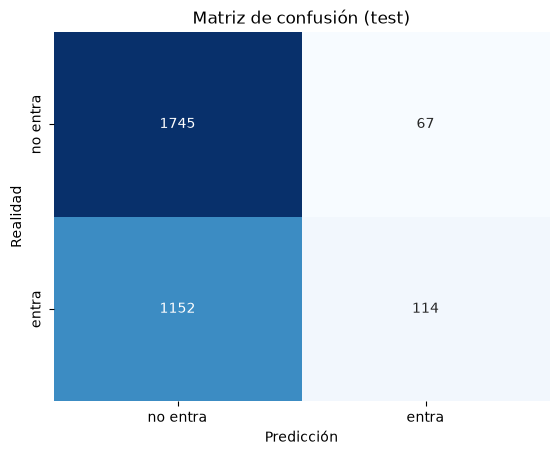

scikit-learn -> accuracy 0.604   precision 0.630   recall 0.090   F1 0.158
AUC: 0.576


In [23]:
scaler = StandardScaler()
X_test_esc = scaler.fit_transform(X_test)
pred_test = mejor_modelo.predict(X_test_esc)     
prob_test = mejor_modelo.predict_proba(X_test_esc)[:, 1]  

cm = confusion_matrix(y_test, pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (test)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_test, pred_test):.3f}   '
      f'precision {precision_score(y_test, pred_test):.3f}   '
      f'recall {recall_score(y_test, pred_test):.3f}   F1 {f1_score(y_test, pred_test):.3f}')

print('AUC:', round(roc_auc_score(y_test, prob_test), 3))

## Guardar modelo:

In [ ]:
joblib.dump(mejor_modelo, "../model/XGBoost_model.joblib")

Modelo guardado correctamente


## Reflexión final:

Tras entrenar y evaluar el modelo XGBoost, se han obtenido resultados moderados, destacando especialmente su recall de 0.697 y su F1-score de 0.573.

El recall es la métrica más destacable de este modelo, ya que permite identificar aproximadamente el 69,7 % de las canciones que realmente alcanzan el Top 30 de Billboard 100. Desde el punto de vista empresarial de la IA, este comportamiento resulta interesante, puesto que uno de los objetivos principales de la discográfica es evitar descartar canciones que podrían tener potencial comercial.

Sin embargo, esta capacidad de detección viene acompañada de una precisión de 0.486. Esto significa que menos de la mitad de las canciones clasificadas como potenciales éxitos realmente pertenecen a la clase positiva. Por tanto, el modelo genera un número considerable de falsas recomendaciones, lo que podría provocar inversiones en canciones que finalmente no alcancen el objetivo esperado.

Por otra parte, el accuracy de 0.572 refleja un rendimiento global limitado, mientras que el ROC-AUC de 0.646 indica que su capacidad para distinguir entre canciones que alcanzan el Top 30 y aquellas que no es relativamente reducida.

En comparación con otros modelos, XGBoost podría resultar interesante si se prioriza la detección de canciones con potencial comercial, debido a su mayor recall. No obstante, su precisión relativamente baja supone una limitación importante para utilizarlo directamente en decisiones de financiación.

En conclusión, considero que XGBoost presenta un comportamiento interesante para el problema planteado, especialmente por su capacidad para identificar una mayor proporción de canciones exitosas. Sin embargo, sus resultados todavía no son suficientemente sólidos para utilizarlo como modelo definitivo. Se podría estudiar la modificación de sus hiperparámetros o el ajuste del umbral de clasificación para intentar mejorar el equilibrio entre recall y precisión.

Por tanto, mantendría este modelo como una alternativa a considerar durante la comparación final, pero no lo seleccionaría únicamente por su recall, sino teniendo en cuenta también los costes empresariales asociados a las falsas recomendaciones.